# Dimensionality Reduction Workflow

This notebook evaluates dimensionality reduction as both a preprocessing step for classifiers and a visualization tool for high-dimensional image data.

## Workflow Overview

**Objective:** test whether reducing feature dimensions improves speed, preserves accuracy, or reveals useful visual structure.

**Dataset:** MNIST digit images.

**Primary metrics:** classifier fit time, prediction time, accuracy, and qualitative 2D cluster separation.

**Validation strategy:** compare raw features against PCA-reduced features using the same downstream classifiers.

**Production mindset:** dimensionality reduction is treated as a design choice that must be measured, not assumed to improve every model.

## Stage 0 - Environment and Runtime Controls

Import dimensionality reduction methods, classifiers, plotting tools, and runtime flags.

In [3]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.manifold import LocallyLinearEmbedding, MDS, TSNE
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Set these to True for the full exercise sizes from the book.
RUN_EXPENSIVE_MNIST = False
RUN_EXPENSIVE_VISUALIZATION = False

MNIST_TRAIN_SIZE = 60_000 if RUN_EXPENSIVE_MNIST else 8_000
MNIST_TEST_SIZE = 10_000 if RUN_EXPENSIVE_MNIST else 2_000
N_ESTIMATORS = 100 if RUN_EXPENSIVE_MNIST else 50

VISUALIZATION_SIZE = 5_000 if RUN_EXPENSIVE_VISUALIZATION else 800

## Stage 1 - Load MNIST

Load image vectors and labels, then create practical subsets for speed-controlled experiments.

The book asks for the standard split:

```text
first 60,000 rows = training
last 10,000 rows = test
```

By default, this notebook uses smaller subsets so it runs quickly. Set `RUN_EXPENSIVE_MNIST = True` for the full classifier experiment and `RUN_EXPENSIVE_VISUALIZATION = True` for the full 5,000-image t-SNE visualization.

In [4]:
mnist = fetch_openml("mnist_784", as_frame=False, parser="auto")
X_mnist = mnist.data.astype(np.float32)
y_mnist = mnist.target.astype(np.uint8)

X_train = X_mnist[:MNIST_TRAIN_SIZE]
y_train = y_mnist[:MNIST_TRAIN_SIZE]
X_test = X_mnist[60_000:60_000 + MNIST_TEST_SIZE]
y_test = y_mnist[60_000:60_000 + MNIST_TEST_SIZE]

X_train.shape, X_test.shape

((8000, 784), (2000, 784))

## Stage 2 - PCA as Model Preprocessing

Compare random forests and SGD classifiers before and after PCA to measure actual speed/accuracy tradeoffs.

We compare:

1. Random forest on original MNIST features
2. Random forest after PCA keeps 95% explained variance
3. SGD classifier on original scaled features
4. SGD classifier after PCA keeps 95% explained variance

The result may surprise you: PCA does not always speed up every model. Random forests can be slower after PCA because PCA creates dense rotated features that may not suit tree splits as well as original pixels. Linear models like SGD often benefit more.

In [5]:
def time_fit_and_score(model, X_train_data, y_train_data, X_test_data, y_test_data):
    start = time.perf_counter()
    model.fit(X_train_data, y_train_data)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test_data)
    predict_time = time.perf_counter() - start

    return {
        "fit_time_seconds": fit_time,
        "predict_time_seconds": predict_time,
        "test_accuracy": accuracy_score(y_test_data, predictions),
    }


results = []

In [6]:
rf_raw = RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1)
rf_raw_result = time_fit_and_score(rf_raw, X_train, y_train, X_test, y_test)
rf_raw_result["model"] = "random_forest_raw"
rf_raw_result["n_features"] = X_train.shape[1]
results.append(rf_raw_result)

rf_raw_result

{'fit_time_seconds': 0.5535345000098459,
 'predict_time_seconds': 0.027278958004899323,
 'test_accuracy': 0.9125,
 'model': 'random_forest_raw',
 'n_features': 784}

In [ ]:
pca_95 = PCA(n_components=0.95, random_state=RANDOM_STATE)
start = time.perf_counter()
X_train_reduced = pca_95.fit_transform(X_train)
X_test_reduced = pca_95.transform(X_test)
pca_fit_transform_time = time.perf_counter() - start

X_train_reduced.shape, pca_fit_transform_time

((8000, 150), 0.20618808298604563)

In [8]:
rf_pca = RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1)
rf_pca_result = time_fit_and_score(rf_pca, X_train_reduced, y_train, X_test_reduced, y_test)
rf_pca_result["model"] = "random_forest_pca_95"
rf_pca_result["n_features"] = X_train_reduced.shape[1]
rf_pca_result["pca_fit_transform_time_seconds"] = pca_fit_transform_time
results.append(rf_pca_result)

rf_pca_result

{'fit_time_seconds': 0.6959144159918651,
 'predict_time_seconds': 0.014136291982140392,
 'test_accuracy': 0.8615,
 'model': 'random_forest_pca_95',
 'n_features': 150,
 'pca_fit_transform_time_seconds': 0.20618808298604563}

In [9]:
sgd_raw = make_pipeline(
    StandardScaler(),
    SGDClassifier(loss="log_loss", max_iter=1_000, tol=1e-2, random_state=RANDOM_STATE, n_jobs=-1),
)
sgd_raw_result = time_fit_and_score(sgd_raw, X_train, y_train, X_test, y_test)
sgd_raw_result["model"] = "sgd_raw_scaled"
sgd_raw_result["n_features"] = X_train.shape[1]
results.append(sgd_raw_result)

sgd_pca = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95, random_state=RANDOM_STATE),
    SGDClassifier(loss="log_loss", max_iter=1_000, tol=1e-2, random_state=RANDOM_STATE, n_jobs=-1),
)
sgd_pca_result = time_fit_and_score(sgd_pca, X_train, y_train, X_test, y_test)
sgd_pca_result["model"] = "sgd_scaled_pca_95"
sgd_pca_result["n_features"] = "PCA 95%"
results.append(sgd_pca_result)

pd.DataFrame(results).set_index("model")

,fit_time_seconds,predict_time_seconds,test_accuracy,n_features,pca_fit_transform_time_seconds
model,,,,,
random_forest_raw,0.553535,0.027279,0.9125,784,NaN
random_forest_pca_95,0.695914,0.014136,0.8615,150,0.206188
sgd_raw_scaled,2.309415,0.012004,0.8700,784,NaN
sgd_scaled_pca_95,1.139126,0.019926,0.8720,PCA 95%,NaN


## Stage 3 - 2D Embedding for Visual Inspection

Map high-dimensional digit images to two dimensions using t-SNE, PCA, LLE, and MDS to inspect class structure.

We reduce a subset of MNIST images to 2D and plot the results.

Methods included:

- t-SNE
- PCA
- LLE
- MDS

For speed, the default visualization subset is smaller than the book's 5,000 images.

In [17]:
X_vis = X_mnist[:5000]
y_vis = y_mnist[:5000]

X_vis.shape, y_vis.shape

((5000, 784), (5000,))

In [18]:
def plot_2d_digits(X_2d, y, title):
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=y,
        cmap="tab10",
        s=12,
        alpha=0.75,
    )
    plt.colorbar(scatter, ticks=range(10), label="Digit")
    plt.title(title)
    plt.xlabel("dimension 1")
    plt.ylabel("dimension 2")
    plt.grid(True, alpha=0.25)
    plt.show()

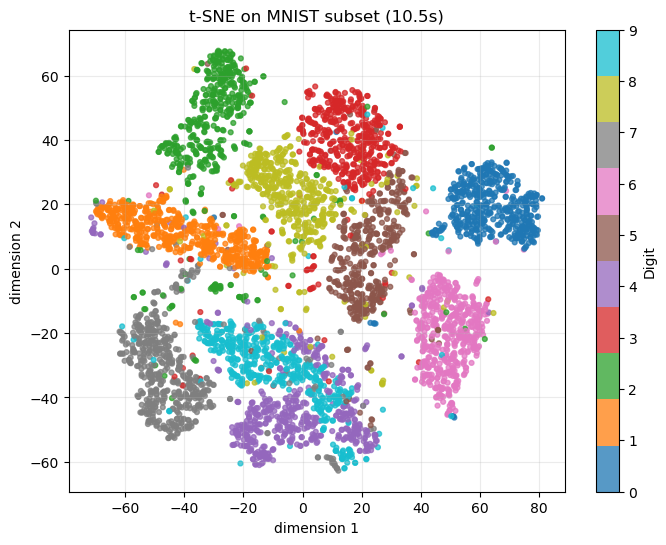

In [19]:
tsne = TSNE(n_components=2, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
start = time.perf_counter()
X_tsne = tsne.fit_transform(X_vis)
tsne_time = time.perf_counter() - start

plot_2d_digits(X_tsne, y_vis, f"t-SNE on MNIST subset ({tsne_time:.1f}s)")

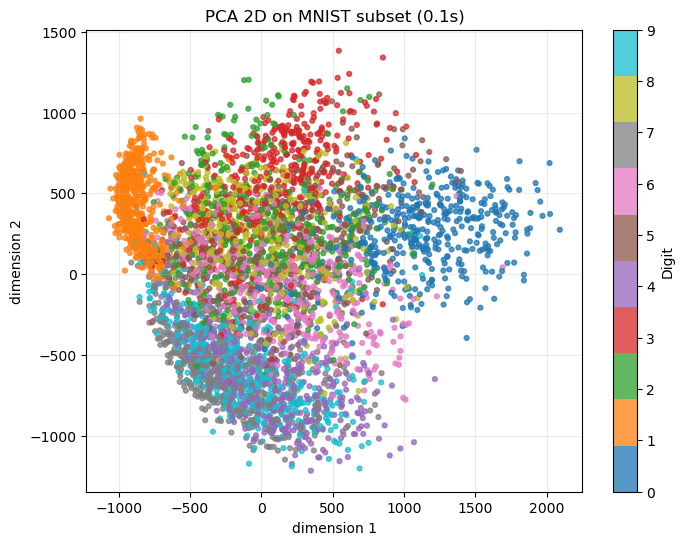

In [20]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
start = time.perf_counter()
X_pca_2d = pca_2d.fit_transform(X_vis)
pca_2d_time = time.perf_counter() - start

plot_2d_digits(X_pca_2d, y_vis, f"PCA 2D on MNIST subset ({pca_2d_time:.1f}s)")

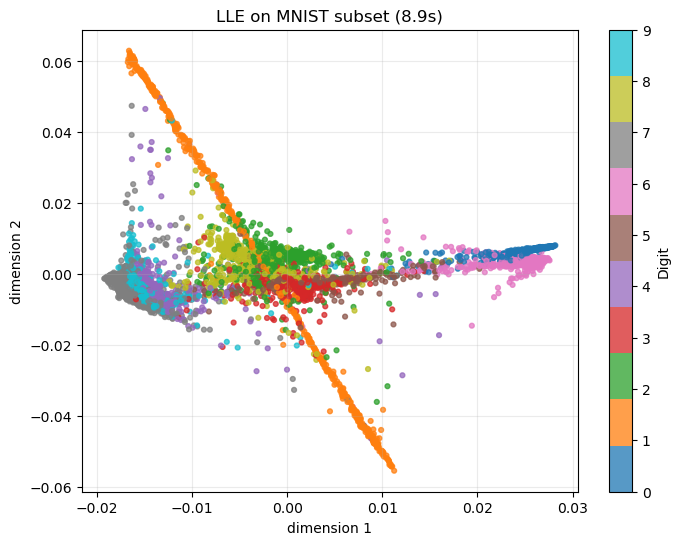

In [21]:
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=RANDOM_STATE)
start = time.perf_counter()
X_lle = lle.fit_transform(X_vis)
lle_time = time.perf_counter() - start

plot_2d_digits(X_lle, y_vis, f"LLE on MNIST subset ({lle_time:.1f}s)")

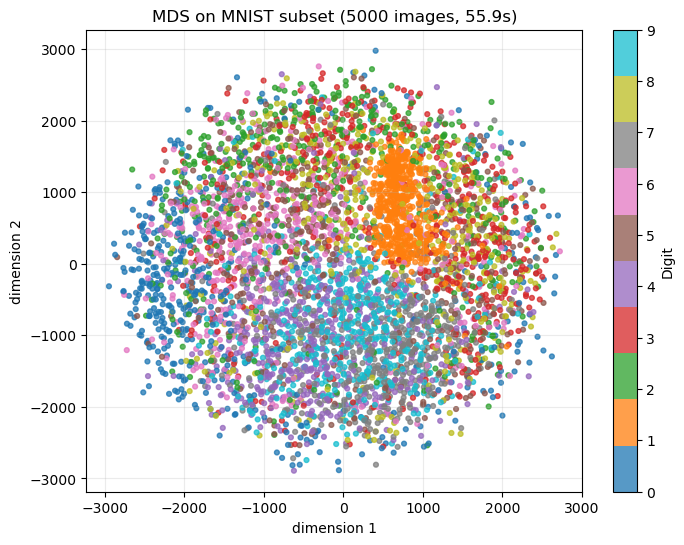

In [24]:
# MDS is comparatively slow, so use an even smaller sample by default.
mds_size = min(5000, len(X_vis)) if not RUN_EXPENSIVE_VISUALIZATION else min(1_000, len(X_vis))
X_mds_input = X_vis[:mds_size]
y_mds = y_vis[:mds_size]

mds = MDS(n_components=2, normalized_stress="auto", random_state=RANDOM_STATE, n_init=1, max_iter=150)
start = time.perf_counter()
X_mds = mds.fit_transform(X_mds_input)
mds_time = time.perf_counter() - start

plot_2d_digits(X_mds, y_mds, f"MDS on MNIST subset ({mds_size} images, {mds_time:.1f}s)")

## Workflow Summary and Next Steps

Summarize when PCA helps, when it hurts, and how visualization methods differ from production preprocessing methods.

Notebook complete.

Key ideas:

- dimensionality reduction can speed up training and help visualization, but loses information
- high-dimensional spaces are sparse, which makes learning harder
- PCA can be reversed approximately with `inverse_transform()`
- PCA is linear, so it may distort nonlinear manifolds
- the number of PCA components for 95% explained variance depends on the data
- PCA is not always faster for every model; evaluate speed and accuracy for your task
- t-SNE is usually better than PCA for 2D visualization of clusters, but it is slower